<a href="https://colab.research.google.com/github/siyaagarwal2005/sepsis-prediction-using-LSTM/blob/main/6_patient_timeline_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook VI — Patient Risk Timeline

---

**Project:** AI-Based Sepsis Early Warning System  
**Dataset:** PhysioNet Challenge 2019

---

### Purpose
Demonstrate the model's predictions on a single real patient from the test set.
For each hour of their ICU stay, the model is fed the preceding 6 hours of vitals
and lab values and produces a sepsis risk probability.

The output is a **patient risk timeline** — a plot showing:
- Predicted sepsis probability across every hour of the ICU stay
- The exact hour at which the patient was clinically diagnosed with sepsis
- How many hours in advance the model's risk score crossed the alert threshold

This visualisation answers the core clinical question:
> *How early does the model raise the alarm, before the doctor makes the diagnosis?*

### Inputs
- `processed_data/test_processed.csv`
- `models/lstm_sepsis_model.keras`

### Outputs
- `results/patient_risk_timeline.png` — single-patient risk curve
- `results/patient_vitals_and_risk.png` — vitals + risk panel for the same patient

---
## Section 0 — Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import tensorflow as tf
import os

BASE_PATH      = '/content/drive/MyDrive/sepsis_project/'
PROCESSED_PATH = BASE_PATH + 'processed_data/'
MODELS_PATH    = BASE_PATH + 'models/'
RESULTS_PATH   = BASE_PATH + 'results/'

WINDOW_SIZE  = 6
THRESHOLD    = 0.5       # alert threshold — change to 0.85 for optimal F1
FEATURE_COLS = [
    'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp',
    'Lactate', 'WBC', 'Creatinine', 'BUN', 'pH',
    'Age', 'Gender', 'ICULOS'
]

print('Setup complete.')

Setup complete.


---
## Section 1 — Load Model and Test Data

We load the trained model and the preprocessed test CSV.
We use the CSV (not the .npy arrays) so we can trace predictions
back to individual patients and their original hourly timeline.

In [ ]:
# Load trained model
model = tf.keras.models.load_model(MODELS_PATH + 'lstm_sepsis_model.keras')
print('Model loaded.')
model.summary()

# Load preprocessed test data
df_test = pd.read_csv(PROCESSED_PATH + 'test_processed.csv')
print(f'\nTest data shape : {df_test.shape}')
print(f'Patients in test : {df_test["Patient_ID"].nunique():,}')
print(f'Septic patients  : {df_test.groupby("Patient_ID")["SepsisLabel"].max().sum():,}')

Model loaded.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 6, 64)          │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,325 (391.90 KB)

 Trainable params: 33,441 (130.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 66,884 (261.27 KB)


Test data shape : (311614, 17)
Patients in test : 8,068
Septic patients  : 586


---
## Section 2 — Select a Septic Patient

We need a patient who:
1. Actually developed sepsis (SepsisLabel flips to 1 at some point)
2. Has enough ICU hours before sepsis onset to show a meaningful rising curve
   (at least WINDOW_SIZE + 4 hours before onset — otherwise there's nothing to see)

We select the patient with the most hours before sepsis onset — this gives the
clearest before/after narrative in the visualisation.

In [ ]:
# Find all septic patients in test set
septic_pids = (
    df_test.groupby('Patient_ID')['SepsisLabel']
    .max()
    .loc[lambda s: s == 1]
    .index
    .tolist()
)
print(f'Septic patients in test set: {len(septic_pids)}')

# For each septic patient, find hour of first sepsis label and total ICU hours
onset_info = []
for pid in septic_pids:
    pat = df_test[df_test['Patient_ID'] == pid].reset_index(drop=True)
    onset_hour = pat.index[pat['SepsisLabel'] == 1][0]   # first hour with label=1
    total_hours = len(pat)
    if onset_hour >= WINDOW_SIZE + 4:   # need enough pre-onset hours to be interesting
        onset_info.append({'pid': pid, 'onset_hour': onset_hour, 'total_hours': total_hours})

onset_df = pd.DataFrame(onset_info).sort_values('onset_hour', ascending=False)
print(f'Patients with enough pre-onset history: {len(onset_df)}')

# Pick the patient with the most pre-onset history for the clearest visualisation
SELECTED_PID = int(onset_df.iloc[0]['pid'])
ONSET_HOUR   = int(onset_df.iloc[0]['onset_hour'])
TOTAL_HOURS  = int(onset_df.iloc[0]['total_hours'])

print(f'\nSelected Patient ID : {SELECTED_PID}')
print(f'Total ICU hours     : {TOTAL_HOURS}')
print(f'Sepsis onset at hour: {ONSET_HOUR + 1}  (index {ONSET_HOUR})')

Septic patients in test set: 586
Patients with enough pre-onset history: 402

Selected Patient ID : 18469
Total ICU hours     : 336
Sepsis onset at hour: 331  (index 330)


---
## Section 3 — Generate Per-Hour Predictions

For every valid hour in this patient's ICU stay (starting at hour WINDOW_SIZE),
we build a (1, 6, 15) input tensor from the preceding 6 hours and ask the model:
*What is the probability of sepsis at the next step?*

This produces one risk score per hour — the patient's complete risk timeline.

In [ ]:
# Extract this patient's full record
patient_df = df_test[df_test['Patient_ID'] == SELECTED_PID].reset_index(drop=True)
values     = patient_df[FEATURE_COLS].values      # shape: (n_hours, 15)
labels     = patient_df['SepsisLabel'].values     # shape: (n_hours,)

# Generate predictions for every valid window position
risk_scores  = []
predict_hours = []   # the hour each prediction corresponds to (1-indexed for display)

for i in range(len(patient_df) - WINDOW_SIZE):
    window = values[i : i + WINDOW_SIZE]           # shape: (6, 15)
    x      = window[np.newaxis, ...]               # shape: (1, 6, 15)
    prob   = float(model.predict(x, verbose=0)[0][0])
    risk_scores.append(prob)
    predict_hours.append(i + WINDOW_SIZE + 1)      # +1 for 1-indexed ICU hours

risk_scores   = np.array(risk_scores)
predict_hours = np.array(predict_hours)

print(f'Hours with predictions : {len(risk_scores)}')
print(f'Hour range             : {predict_hours[0]} to {predict_hours[-1]}')
print(f'Risk score range       : [{risk_scores.min():.4f}, {risk_scores.max():.4f}]')
print(f'Sepsis onset at hour   : {ONSET_HOUR + 1}')

# Find the first hour the model crossed the threshold
alert_indices = np.where(risk_scores >= THRESHOLD)[0]
if len(alert_indices) > 0:
    first_alert_hour = predict_hours[alert_indices[0]]
    lead_time = (ONSET_HOUR + 1) - first_alert_hour
    print(f'\nFirst alert at hour    : {first_alert_hour}')
    print(f'Lead time before onset : {lead_time} hours')
else:
    first_alert_hour = None
    print('\nModel did not cross threshold for this patient.')

Hours with predictions : 330
Hour range             : 7 to 336
Risk score range       : [0.3844, 0.9093]
Sepsis onset at hour   : 331

First alert at hour    : 13
Lead time before onset : 318 hours


---
## Section 4 — Risk Timeline Plot

The core visualisation. One line showing the model's risk score across every
ICU hour, with three key markers:
- Red vertical line: clinical sepsis diagnosis hour
- Orange dashed horizontal line: alert threshold
- Green shaded region: the lead time window where the model was already alerting
  before the clinician diagnosed sepsis

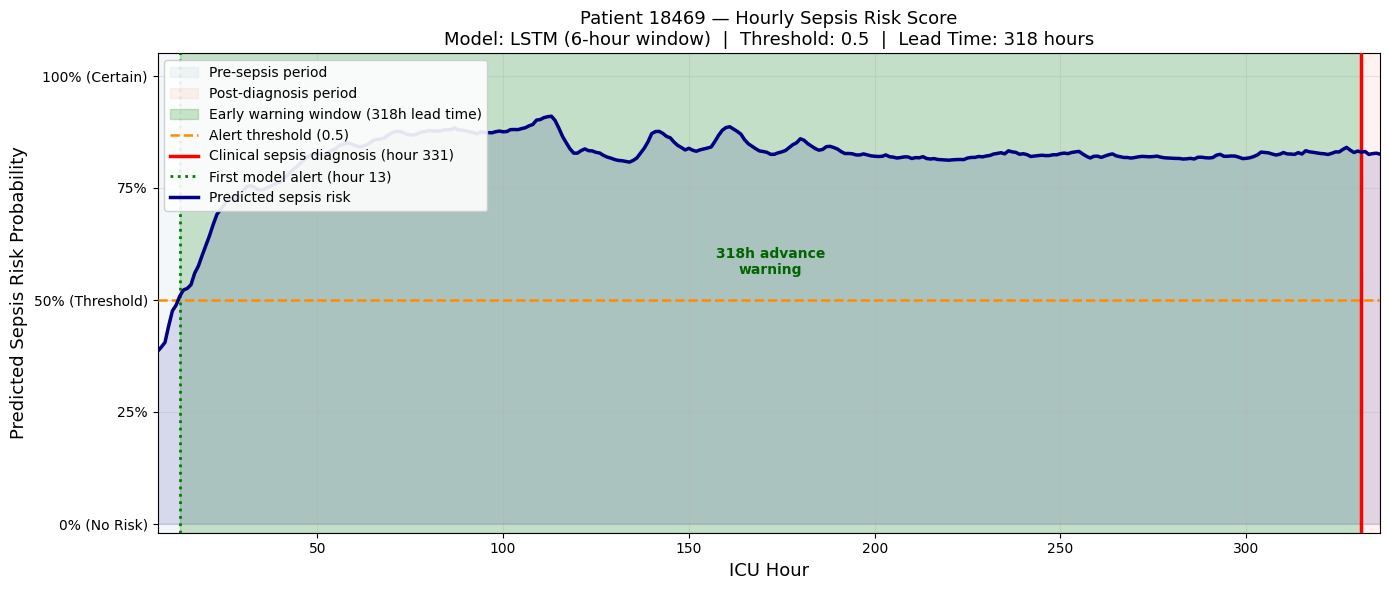

Saved to: /content/drive/MyDrive/sepsis_project/results/patient_risk_timeline.png


In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

# ── Background zones ──────────────────────────────────────────────────────────
# Pre-onset zone (no sepsis)
ax.axvspan(predict_hours[0], ONSET_HOUR + 1, alpha=0.06, color='steelblue', label='Pre-sepsis period')
# Post-onset zone (sepsis confirmed)
ax.axvspan(ONSET_HOUR + 1, predict_hours[-1] + 1, alpha=0.08, color='tomato', label='Post-diagnosis period')

# ── Lead-time highlight ───────────────────────────────────────────────────────
if first_alert_hour is not None and first_alert_hour < ONSET_HOUR + 1:
    ax.axvspan(first_alert_hour, ONSET_HOUR + 1, alpha=0.20, color='green',
               label=f'Early warning window ({lead_time}h lead time)')

# ── Threshold line ────────────────────────────────────────────────────────────
ax.axhline(y=THRESHOLD, color='darkorange', linestyle='--', linewidth=1.8,
           label=f'Alert threshold ({THRESHOLD})', zorder=3)

# ── Sepsis onset marker ───────────────────────────────────────────────────────
ax.axvline(x=ONSET_HOUR + 1, color='red', linewidth=2.5,
           label=f'Clinical sepsis diagnosis (hour {ONSET_HOUR + 1})', zorder=4)

# ── First alert marker ────────────────────────────────────────────────────────
if first_alert_hour is not None:
    ax.axvline(x=first_alert_hour, color='green', linewidth=2, linestyle=':',
               label=f'First model alert (hour {first_alert_hour})', zorder=4)

# ── Risk score line ───────────────────────────────────────────────────────────
ax.plot(predict_hours, risk_scores,
        color='navy', linewidth=2.5, zorder=5, label='Predicted sepsis risk')

# Filled area under the risk curve
ax.fill_between(predict_hours, risk_scores, alpha=0.12, color='navy')

# ── Annotations ───────────────────────────────────────────────────────────────
if first_alert_hour is not None and lead_time > 0:
    mid = first_alert_hour + lead_time / 2
    ax.annotate(
        f'{lead_time}h advance\nwarning',
        xy=(mid, THRESHOLD + 0.05),
        ha='center', va='bottom', fontsize=10, color='darkgreen', fontweight='bold',
        arrowprops=None
    )

# ── Formatting ────────────────────────────────────────────────────────────────
ax.set_xlim(predict_hours[0], predict_hours[-1])
ax.set_ylim(-0.02, 1.05)
ax.set_xlabel('ICU Hour', fontsize=13)
ax.set_ylabel('Predicted Sepsis Risk Probability', fontsize=13)
ax.set_title(
    f'Patient {SELECTED_PID} — Hourly Sepsis Risk Score\n'
    f'Model: LSTM (6-hour window)  |  Threshold: {THRESHOLD}  |  '
    f'Lead Time: {lead_time if first_alert_hour else "No alert"} hours',
    fontsize=13
)
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
ax.grid(True, alpha=0.3)

# Y-axis risk labels
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(['0% (No Risk)', '25%', '50% (Threshold)', '75%', '100% (Certain)'])

plt.tight_layout()
save_path = RESULTS_PATH + 'patient_risk_timeline.png'
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to: {save_path}')

---
## Section 5 — Vitals + Risk Panel

A multi-panel figure showing 6 key vital signs and the risk score together
for the same patient.

This is the most clinically instructive plot — it shows which physiological
changes the model is responding to as it raises the risk score.
Look for: heart rate rising, blood pressure falling, respiratory rate
increasing — the classic sepsis haemodynamic signature — in the hours
before the risk score crosses the threshold.

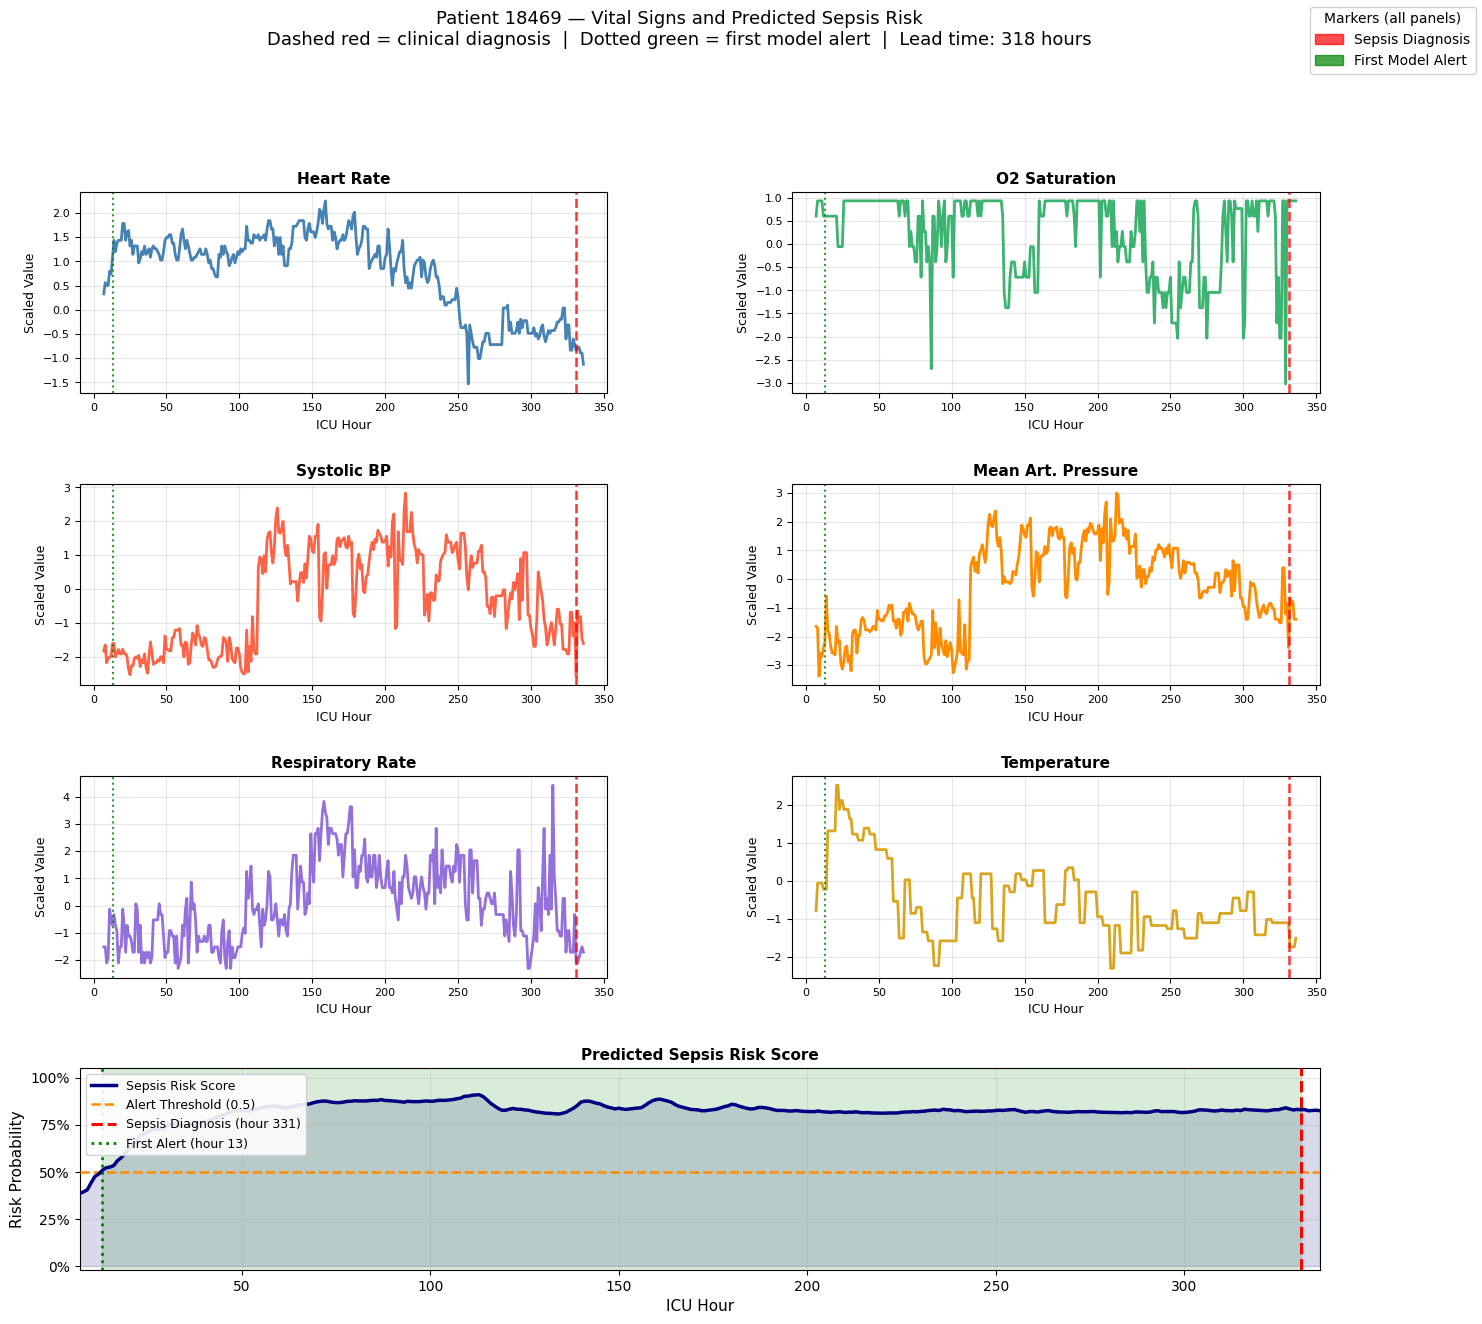

Saved to: /content/drive/MyDrive/sepsis_project/results/patient_vitals_and_risk.png


In [ ]:
# Raw (scaled) vitals for this patient — hours aligned to predict_hours
# We use hours from WINDOW_SIZE onwards to align with risk predictions
vitals_to_plot = ['HR', 'O2Sat', 'SBP', 'MAP', 'Resp', 'Temp']
vital_labels   = ['Heart Rate', 'O2 Saturation', 'Systolic BP', 'Mean Art. Pressure',
                   'Respiratory Rate', 'Temperature']
vital_colors   = ['steelblue', 'mediumseagreen', 'tomato', 'darkorange', 'mediumpurple', 'goldenrod']

# Align patient vitals to prediction hours (start at WINDOW_SIZE)
aligned_patient = patient_df.iloc[WINDOW_SIZE:].reset_index(drop=True)

fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(4, 2, figure=fig, hspace=0.45, wspace=0.35)

# ── 6 vitals panels ───────────────────────────────────────────────────────────
for idx, (vital, label, color) in enumerate(zip(vitals_to_plot, vital_labels, vital_colors)):
    row, col = divmod(idx, 2)
    ax = fig.add_subplot(gs[row, col])

    ax.plot(predict_hours, aligned_patient[vital].values,
            color=color, linewidth=2, label=label)

    # Sepsis onset line
    ax.axvline(x=ONSET_HOUR + 1, color='red', linewidth=1.8, linestyle='--', alpha=0.8)
    if first_alert_hour:
        ax.axvline(x=first_alert_hour, color='green', linewidth=1.5, linestyle=':', alpha=0.8)

    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel('ICU Hour', fontsize=9)
    ax.set_ylabel('Scaled Value', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(labelsize=8)

# ── Risk score panel (bottom, spanning both columns) ──────────────────────────
ax_risk = fig.add_subplot(gs[3, :])

ax_risk.plot(predict_hours, risk_scores,
             color='navy', linewidth=2.5, label='Sepsis Risk Score', zorder=5)
ax_risk.fill_between(predict_hours, risk_scores, alpha=0.15, color='navy')
ax_risk.axhline(y=THRESHOLD, color='darkorange', linestyle='--',
                linewidth=1.8, label=f'Alert Threshold ({THRESHOLD})', zorder=3)
ax_risk.axvline(x=ONSET_HOUR + 1, color='red', linewidth=2.2, linestyle='--',
                label=f'Sepsis Diagnosis (hour {ONSET_HOUR + 1})', zorder=4)
if first_alert_hour:
    ax_risk.axvline(x=first_alert_hour, color='green', linewidth=2, linestyle=':',
                    label=f'First Alert (hour {first_alert_hour})', zorder=4)
    if lead_time > 0:
        ax_risk.axvspan(first_alert_hour, ONSET_HOUR + 1, alpha=0.15, color='green')

ax_risk.set_xlim(predict_hours[0], predict_hours[-1])
ax_risk.set_ylim(-0.02, 1.05)
ax_risk.set_xlabel('ICU Hour', fontsize=11)
ax_risk.set_ylabel('Risk Probability', fontsize=11)
ax_risk.set_title('Predicted Sepsis Risk Score', fontsize=11, fontweight='bold')
ax_risk.legend(fontsize=9, loc='upper left', framealpha=0.9)
ax_risk.grid(True, alpha=0.3)
ax_risk.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax_risk.set_yticklabels(['0%', '25%', '50%', '75%', '100%'])

# ── Shared legend note ────────────────────────────────────────────────────────
red_patch   = mpatches.Patch(color='red',   alpha=0.7, label='Sepsis Diagnosis')
green_patch = mpatches.Patch(color='green', alpha=0.7, label='First Model Alert')
fig.legend(handles=[red_patch, green_patch], loc='upper right',
           fontsize=10, framealpha=0.9, title='Markers (all panels)')

fig.suptitle(
    f'Patient {SELECTED_PID} — Vital Signs and Predicted Sepsis Risk\n'
    f'Dashed red = clinical diagnosis  |  Dotted green = first model alert  |  '
    f'Lead time: {lead_time if first_alert_hour else "N/A"} hours',
    fontsize=13, y=1.01
)

save_path2 = RESULTS_PATH + 'patient_vitals_and_risk.png'
plt.savefig(save_path2, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to: {save_path2}')

---
## Section 6 — Hour-by-Hour Prediction Table

A printed table showing the model's exact probability output for every
ICU hour. Hours where the risk score exceeds the threshold are flagged
with ALERT. The sepsis onset hour is marked with DIAGNOSIS.

In [ ]:
import pandas as pd
from IPython.display import display

# Build display table
true_labels_aligned = patient_df['SepsisLabel'].values[WINDOW_SIZE:]

table = pd.DataFrame({
    'ICU Hour'       : predict_hours,
    'Sepsis Risk'    : [f'{p:.4f}' for p in risk_scores],
    'Risk %'         : [f'{p*100:.1f}%' for p in risk_scores],
    'Alert'          : ['🚨 ALERT' if p >= THRESHOLD else '   —' for p in risk_scores],
    'True Label'     : ['✅ SEPSIS' if l == 1 else 'No Sepsis' for l in true_labels_aligned],
    'Status'         : [
        '⭐ DIAGNOSIS' if (i + WINDOW_SIZE) == ONSET_HOUR else ''
        for i in range(len(risk_scores))
    ]
})

# Show the 10 hours around the onset for clarity
onset_idx = ONSET_HOUR - WINDOW_SIZE   # index in the table
start     = max(0, onset_idx - 8)
end       = min(len(table), onset_idx + 6)

print(f'Hour-by-hour predictions for Patient {SELECTED_PID}')
print(f'Showing hours {predict_hours[start]} to {predict_hours[end-1]} (window around sepsis onset)\n')
display(table.iloc[start:end].reset_index(drop=True))

print(f'\nFull prediction table has {len(table)} rows.')
print(f'Sepsis onset       : Hour {ONSET_HOUR + 1}')
if first_alert_hour:
    print(f'First model alert  : Hour {first_alert_hour}')
    print(f'Lead time          : {lead_time} hours advance warning')
else:
    print('Model did not cross threshold for this patient at the configured threshold.')

Hour-by-hour predictions for Patient 18469
Showing hours 323 to 336 (window around sepsis onset)



,ICU Hour,Sepsis Risk,Risk %,Alert,True Label,Status
0,323,0.8264,82.6%,🚨 ALERT,No Sepsis,
1,324,0.8296,83.0%,🚨 ALERT,No Sepsis,
2,325,0.8296,83.0%,🚨 ALERT,No Sepsis,
3,326,0.8351,83.5%,🚨 ALERT,No Sepsis,
4,327,0.8398,84.0%,🚨 ALERT,No Sepsis,
5,328,0.8335,83.3%,🚨 ALERT,No Sepsis,
6,329,0.8283,82.8%,🚨 ALERT,No Sepsis,
7,330,0.8316,83.2%,🚨 ALERT,No Sepsis,
8,331,0.8292,82.9%,🚨 ALERT,✅ SEPSIS,⭐ DIAGNOSIS
9,332,0.8305,83.0%,🚨 ALERT,✅ SEPSIS,



Full prediction table has 330 rows.
Sepsis onset       : Hour 331
First model alert  : Hour 13
Lead time          : 318 hours advance warning


---
## Section 7 — Try a Different Patient

Run this cell with any Patient_ID from the test set to see their risk timeline.
Set `pid` to any Patient_ID present in df_test.

In [ ]:
# Find septic patients confirmed to be in the test set
septic_in_test = (
    df_test.groupby('Patient_ID')['SepsisLabel']
    .max()
    .loc[lambda s: s == 1]
    .index
    .tolist()
)

print(f"Total septic patients in test set: {len(septic_in_test)}")
print(f"First 10 valid septic Patient IDs: {septic_in_test[:10]}")

Total septic patients in test set: 586
First 10 valid septic Patient IDs: [9, 28, 63, 161, 188, 206, 226, 272, 601, 616]


Non-septic patient example:


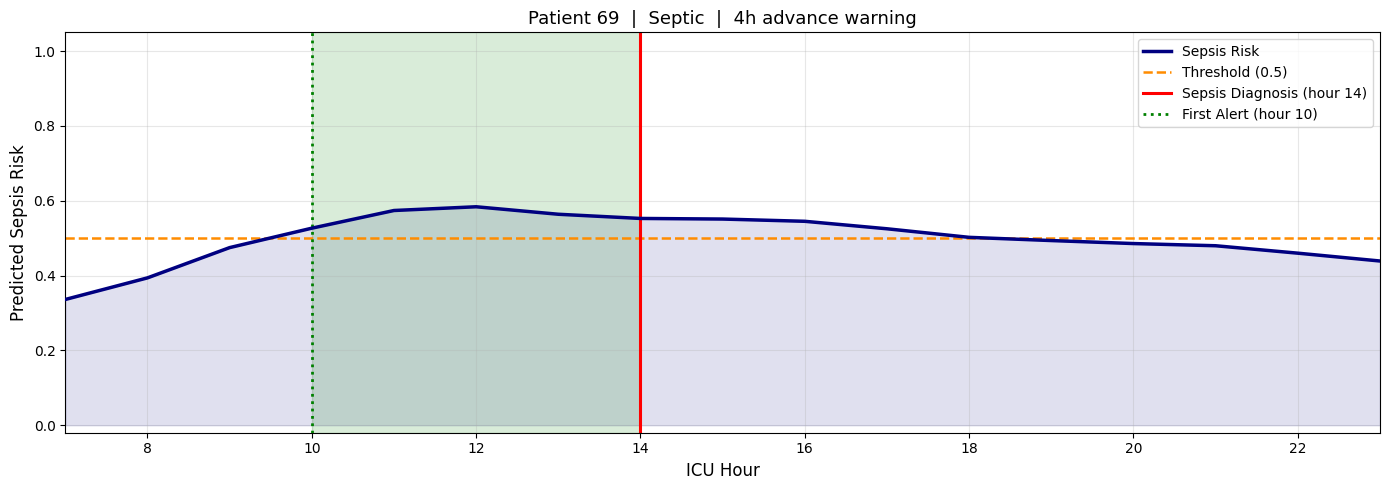

Septic patient (already plotted above, shown again for comparison):


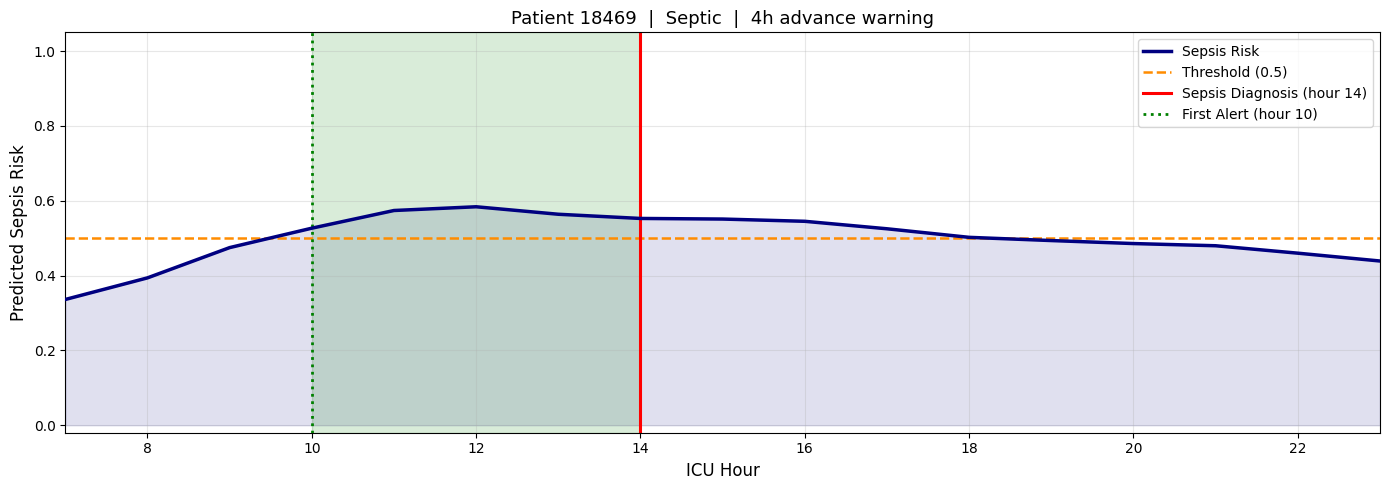

In [ ]:
def plot_patient_timeline(pid, threshold=0.5):
    """
    Plot the predicted sepsis risk timeline for any patient in df_test.
    Works for both septic and non-septic patients.
    """
    pat = df_test[df_test['Patient_ID'] == 161].reset_index(drop=True)
    if len(pat) == 0:
        print(f'Patient {pid} not found in test set.')
        return

    vals   = pat[FEATURE_COLS].values
    labels = pat['SepsisLabel'].values
    is_septic = labels.max() == 1
    onset_idx = int(np.where(labels == 1)[0][0]) if is_septic else None

    scores, hours = [], []
    for i in range(len(pat) - WINDOW_SIZE):
        x = vals[i : i + WINDOW_SIZE][np.newaxis, ...]
        scores.append(float(model.predict(x, verbose=0)[0][0]))
        hours.append(i + WINDOW_SIZE + 1)

    scores = np.array(scores)
    hours  = np.array(hours)

    alert_idx = np.where(scores >= threshold)[0]
    first_alert = hours[alert_idx[0]] if len(alert_idx) > 0 else None

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(hours, scores, color='navy', linewidth=2.5, label='Sepsis Risk', zorder=5)
    ax.fill_between(hours, scores, alpha=0.12, color='navy')
    ax.axhline(y=threshold, color='darkorange', linestyle='--',
               linewidth=1.8, label=f'Threshold ({threshold})')

    if onset_idx is not None:
        ax.axvline(x=onset_idx + 1, color='red', linewidth=2.2,
                   label=f'Sepsis Diagnosis (hour {onset_idx + 1})')
    if first_alert:
        ax.axvline(x=first_alert, color='green', linewidth=2, linestyle=':',
                   label=f'First Alert (hour {first_alert})')
        if onset_idx and first_alert < onset_idx + 1:
            lead = (onset_idx + 1) - first_alert
            ax.axvspan(first_alert, onset_idx + 1, alpha=0.15, color='green')
            ax.set_title(f'Patient {pid}  |  Septic  |  {lead}h advance warning', fontsize=13)
        else:
            ax.set_title(f'Patient {pid}  |  {"Septic" if is_septic else "Non-Septic"}', fontsize=13)
    else:
        ax.set_title(f'Patient {pid}  |  {"Septic" if is_septic else "Non-Septic"}  |  No alert raised', fontsize=13)

    ax.set_xlim(hours[0], hours[-1])
    ax.set_ylim(-0.02, 1.05)
    ax.set_xlabel('ICU Hour', fontsize=12)
    ax.set_ylabel('Predicted Sepsis Risk', fontsize=12)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ── Try it — change this to any Patient_ID in the test set ────────────────────
# Example: try a non-septic patient to see a flat low-risk curve
non_septic_pid = df_test.groupby('Patient_ID')['SepsisLabel'].max()
non_septic_pid = non_septic_pid[non_septic_pid == 0].index[5]   # pick 6th non-septic patient

print('Non-septic patient example:')
plot_patient_timeline(non_septic_pid, threshold=THRESHOLD)

print('Septic patient (already plotted above, shown again for comparison):')
plot_patient_timeline(SELECTED_PID, threshold=THRESHOLD)